In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.preprocessing import RobustScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
dataset_candidates = [
    Path("data/powerconsumption.csv"),
    Path("backend/data/powerconsumption.csv"),
    Path("../data/powerconsumption.csv"),
    Path("powerconsumption.csv"),
]
dataset_path = next((path for path in dataset_candidates if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Could not find powerconsumption.csv in the expected project paths.")
df = pd.read_csv(dataset_path)

print("Shape:", df.shape)

display(df.head())
df.info()

Shape: (52416, 9)


<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 4.3 MB


In [4]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate Rows: {duplicate_count}")

missing_count = df.isnull().sum()
print(missing_count)

Duplicate Rows: 0
Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64


In [5]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
)

df.drop_duplicates(inplace=True)

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df.dropna(subset=["datetime"], inplace=True)

numeric_columns = df.columns.drop("datetime")
df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df.sort_values("datetime", inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"Final Shape: {df.shape}")

display(df.select_dtypes(include=np.number).skew().sort_values(key=abs, ascending=False)
)

Final Shape: (52416, 9)


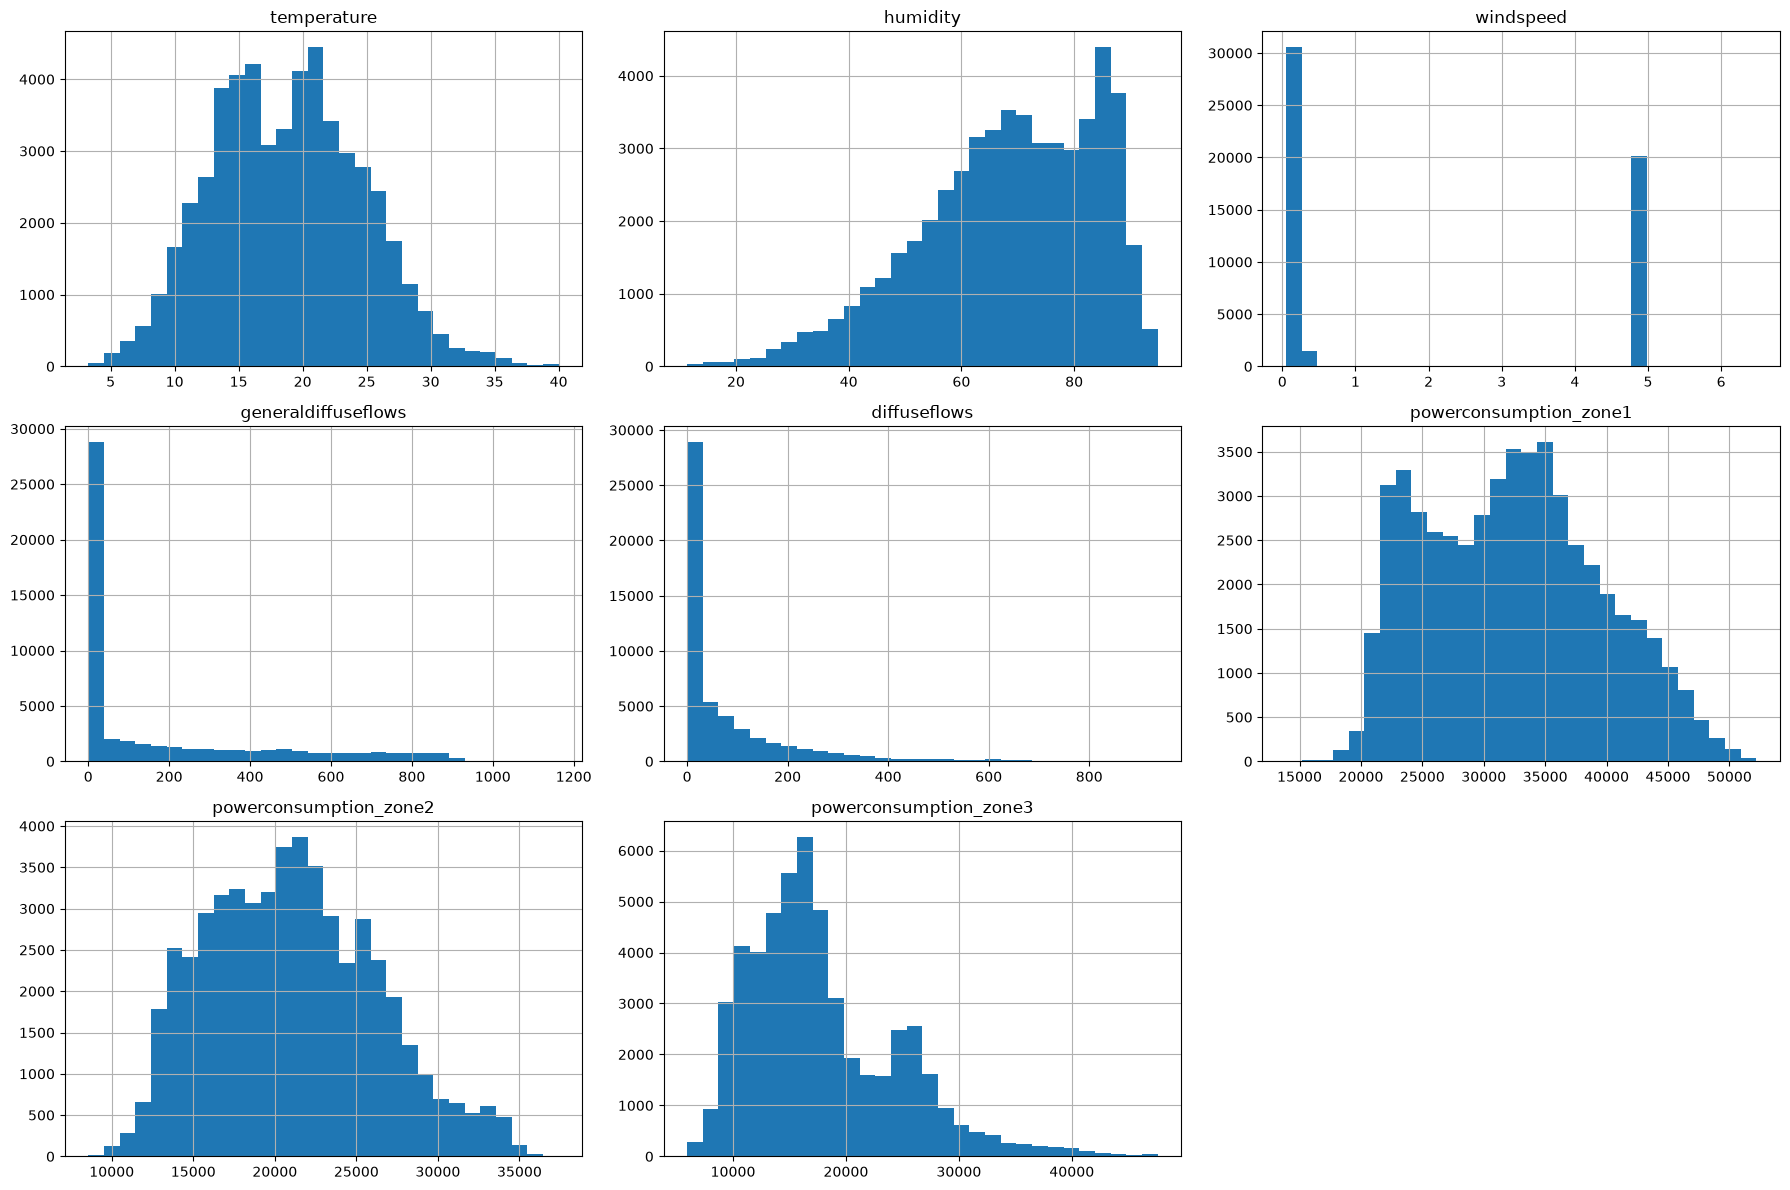

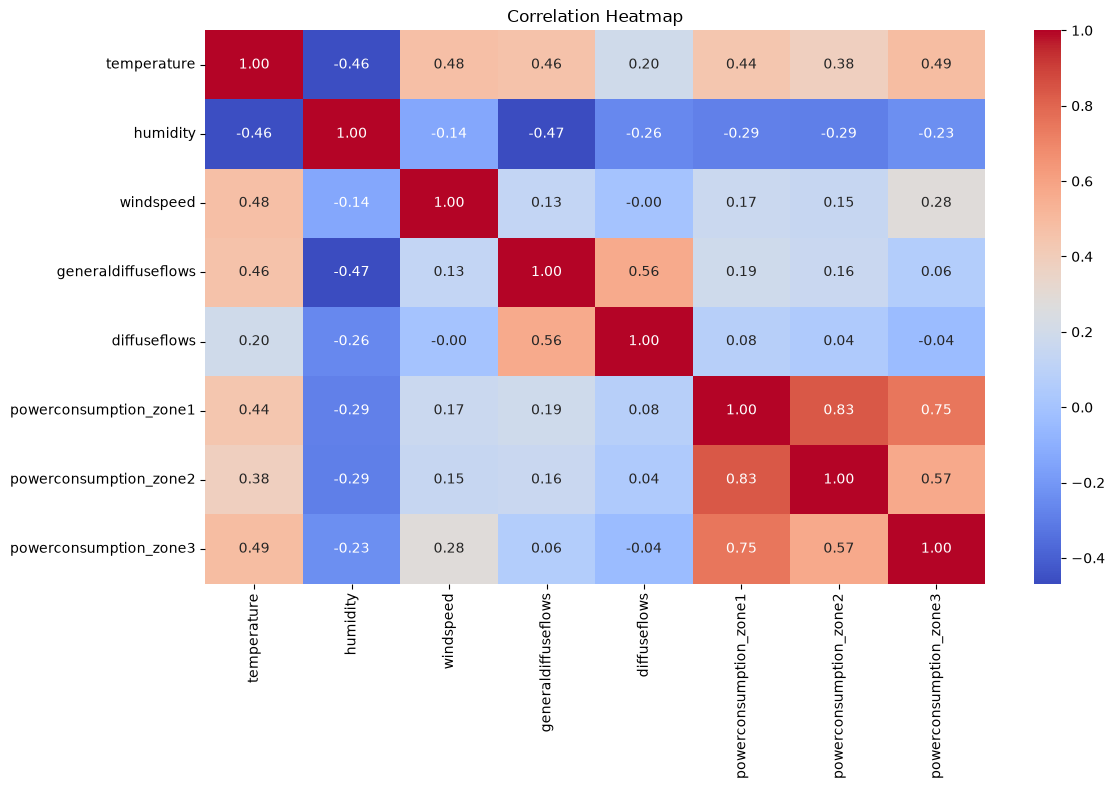

In [6]:
datetime_column = "datetime"
target_column = "zone_1_power_consumption"

df.select_dtypes(include=np.number).hist(
    bins=30,
    figsize=(18, 12)
)

plt.title("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [7]:
datetime_column = "datetime"
target_column = "powerconsumption_zone1"

df["month"] = df[datetime_column].dt.month
df["day_of_week"] = df[datetime_column].dt.dayofweek
df["hour"] = df[datetime_column].dt.hour
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)
df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

df["day_sin"] = np.sin(
    2 * np.pi * df["day_of_week"] / 7
)
df["day_cos"] = np.cos(
    2 * np.pi * df["day_of_week"] / 7
)

df["month_sin"] = np.sin(
    2 * np.pi * df["month"] / 12
)
df["month_cos"] = np.cos(
    2 * np.pi * df["month"] / 12
)

df["total_solar_flow"] = (
    df["generaldiffuseflows"] +
    df["diffuseflows"]
)

df["temperature_humidity"] = (
    df["temperature"] *
    df["humidity"]
)

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

excluded_columns = [
    datetime_column,
    "powerconsumption_zone1",
    "powerconsumption_zone2",
    "powerconsumption_zone3"
]

X = df.drop(columns=excluded_columns)
y = df[target_column]

print("Feature Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())
display(y.head())

Feature Dataset Shape: (52416, 17)
Target Shape: (52416,)


In [8]:
split = int(len(X) * 0.8)

X_train = X.iloc[:split].reset_index(drop=True)
X_test = X.iloc[split:].reset_index(drop=True)

y_train = y.iloc[:split].reset_index(drop=True)
y_test = y.iloc[split:].reset_index(drop=True)

constant_features = [
    col for col in X_train.columns
    if X_train[col].nunique() <= 1
]

if constant_features:
    X_train.drop(columns=constant_features, inplace=True)
    X_test.drop(columns=constant_features, inplace=True)

binary_features = [
    col for col in X_train.columns
    if set(X_train[col].unique()).issubset({0, 1})
]

continuous_features = [
    col for col in X_train.columns
    if col not in binary_features
]

scaler = RobustScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

X_test_scaled[continuous_features] = scaler.transform(
    X_test[continuous_features]
)

print("Training Dataset:", X_train_scaled.shape)
print("Testing Dataset:", X_test_scaled.shape)

display(X_train_scaled.head())
display(y_train.head())

Training Dataset: (41932, 17)
Testing Dataset: (10484, 17)


In [9]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "SVR": SVR(
        kernel="rbf"
    )
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(
        X_train_scaled,
        y_train
    )

    y_pred = model.predict(
        X_test_scaled
    )

    predictions[name] = y_pred

    print(f"{name} completed")

Linear Regression completed
Decision Tree completed
Random Forest completed
SVR completed


In [10]:
for name, y_pred in predictions.items():

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    mse = mean_squared_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        y_pred
    )

    results[name] = [
        mae,
        mse,
        rmse,
        r2
    ]


results_df = pd.DataFrame(
    results,
    index=[
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score",
    ]
).T


display(results_df.sort_values(
    by="RMSE"
))

,MAE,MSE,RMSE,R2 Score
Linear Regression,2421.064659,9.633303e+06,3103.756219,0.746654
Random Forest,4132.305887,2.183694e+07,4673.001542,0.425711
Decision Tree,4355.252079,2.655321e+07,5152.980413,0.301678
SVR,5031.624989,3.421327e+07,5849.211170,0.100226


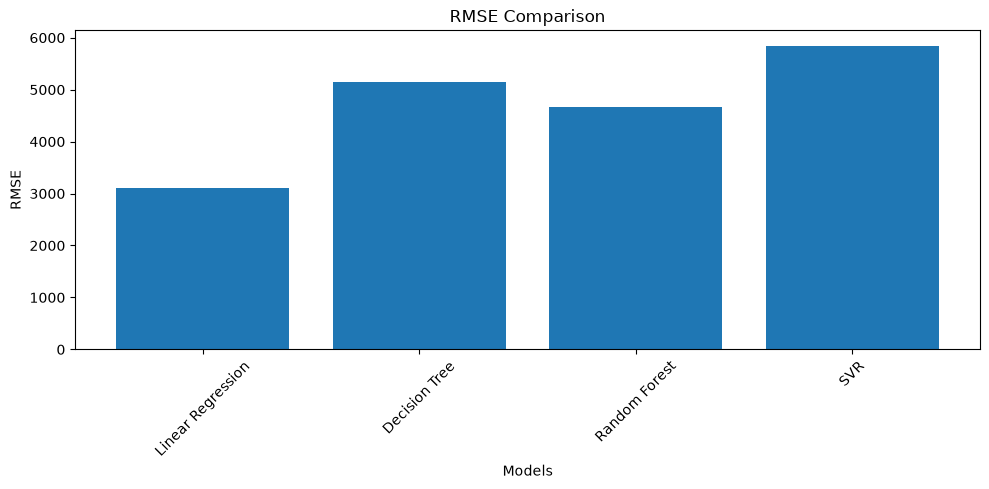

In [11]:
plt.figure(figsize=(10,5))

plt.bar(
    results_df.index,
    results_df["RMSE"]
)

plt.title(
    "RMSE Comparison"
)

plt.xlabel(
    "Models"
)

plt.ylabel(
    "RMSE"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

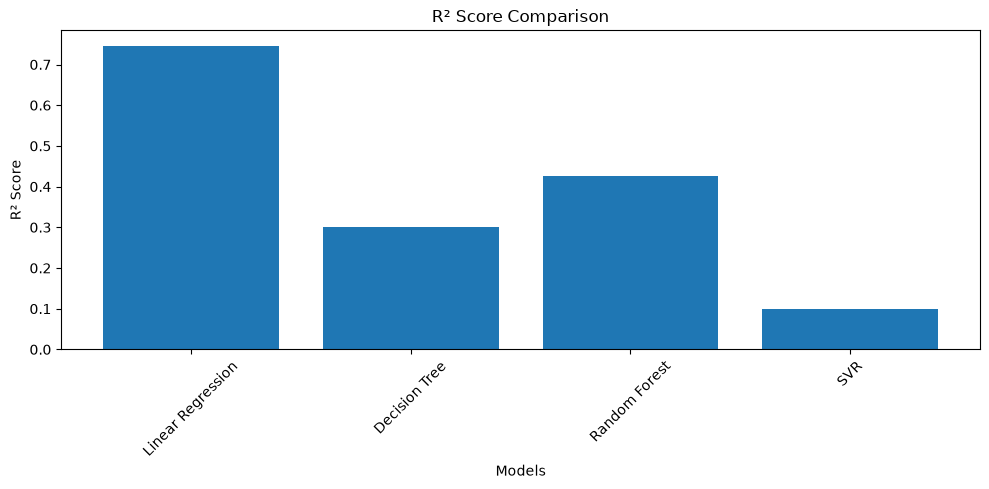

In [12]:
plt.figure(figsize=(10,5))

plt.bar(
    results_df.index,
    results_df["R2 Score"]
)

plt.title(
    "R² Score Comparison"
)

plt.xlabel(
    "Models"
)

plt.ylabel(
    "R² Score"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

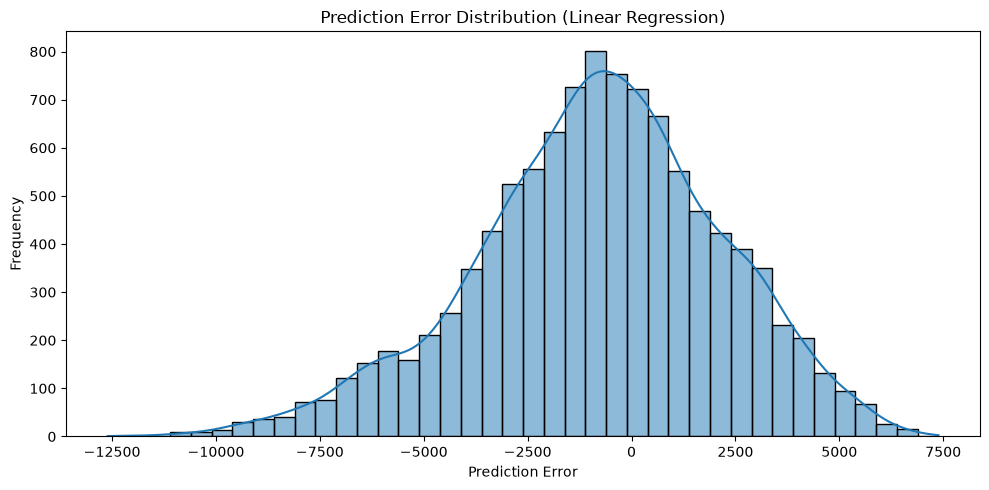

In [13]:
best_model_name = results_df["RMSE"].idxmin()

errors = y_test.values - predictions[best_model_name]

plt.figure(figsize=(10, 5))

sns.histplot(
    errors,
    bins=40,
    kde=True
)

plt.title(
    f"Prediction Error Distribution ({best_model_name})"
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [16]:
best_model = models[best_model_name]

model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": X_train.columns.tolist(),
    "scaler": scaler,
    "metrics": results_df.loc[best_model_name].to_dict()
}

backend_root_candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
    Path.cwd() / "backend",
]
backend_root = next(
    (
        path
        for path in backend_root_candidates
        if (path / "app").is_dir() and (path / "requirements.txt").is_file()
    ),
    Path.cwd(),
)
model_output_path = backend_root / "app" / "models" / "best_model.joblib"
model_output_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model_package, model_output_path)

print(f"Best Model Saved: {best_model_name}")

Best Model Saved: Linear Regression
